# Profile da Simulação — cProfile + Flamegraph

Perfila uma **simulação TOD leve** (GPS, janela curta) para entender onde o
tempo é gasto, usando ferramentas complementares:

1. **`cProfile`** (stdlib) — perfil determinístico com contagem de chamadas.
2. **`pstats`** (stdlib) — análise do `.prof` (top funções por tempo cumulativo/próprio).
3. **flamegraph SVG** — gerado a partir do `.prof` (helper local, sem
   dependência extra; trata recursão, threads e módulos via `exec()`).
4. **`pyinstrument`** — relatório interativo (HTML) de baixo overhead.

> Requisito: `pyinstrument` instalado no ambiente
> (`uv pip install pyinstrument`).

In [1]:
# ── Âncora de diretório + imports ──
import os

from radioskysims_core.paths import get_project_root

os.chdir(get_project_root())

import cProfile
import pstats
from datetime import UTC, datetime, timedelta
from pathlib import Path

from radioskysims_core.domain.common import FrequencyRange, TimeRange
from radioskysims_simulation.bootstrap.composition import create_sim_orchestrator

PROF_DIR = Path("data") / "profiling"
PROF_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# ── Compatibilidade async + credenciais ──
import nest_asyncio

nest_asyncio.apply()

from dotenv import load_dotenv

load_dotenv(get_project_root() / "credentials.env", override=False)
print("✅ ambiente preparado")


✅ ambiente preparado


In [3]:
# ── Parâmetros leves (mesma janela do 02_sims) ──
REF_DATE = (datetime.now(UTC) - timedelta(days=30)).replace(microsecond=0)
_ISO = "%Y-%m-%dT%H:%M:%S"
TR = TimeRange.from_iso(
    REF_DATE.strftime(_ISO),
    (REF_DATE + timedelta(minutes=60)).strftime(_ISO),
    60,
)
FR = FrequencyRange(min_mhz=1000.0, max_mhz=1250.0, resolution_mhz=0.5)

orch = create_sim_orchestrator(telescope="default")
print("TimeRange:", TR.to_datetime64().shape[0], "instantes")
print("Orquestrador pronto")


TimeRange: 61 instantes
Orquestrador pronto


In [4]:
# ── cProfile: coleta do perfil da simulação ──
import time

pr = cProfile.Profile()
pr.enable()
t0 = time.monotonic()
result = orch.run(
    constellations=["GPS"],
    time_range=TR,
    include_satellites=True,
    include_local_sources=False,
    include_radio_sources=False,
    use_processor=True,
)
pr.disable()
elapsed = time.monotonic() - t0
print(f"⏱ run() completou em {elapsed:.1f}s (perfilado)")

prof_path = PROF_DIR / "simulation.prof"
pr.dump_stats(str(prof_path))
print("Perfil salvo em", prof_path)


⏱ run() completou em 38.6s (perfilado)
Perfil salvo em data/profiling/simulation.prof


In [5]:
# ── pstats: top funções ──
stats = pstats.Stats(str(prof_path))
stats.strip_dirs().sort_stats("cumulative").print_stats(25)

print("\n--- Top por tempo próprio (tottime) ---")
stats.sort_stats("tottime").print_stats(15)


Sat Nov  7 02:50:37 2026    data/profiling/simulation.prof

         40183543 function calls (39907130 primitive calls) in 38.534 seconds

   Ordered by: cumulative time
   List reduced from 5892 to 25 due to restriction <25>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      4/3    0.000    0.000   38.126   12.709 interactiveshell.py:3636(run_code)
    476/3    0.018    0.000   38.126   12.709 {built-in method builtins.exec}
      2/1    0.001    0.001   38.050   38.050 sim_orchestrator.py:491(run)
        1    0.002    0.002   34.892   34.892 sim_orchestrator.py:1112(_run_with_processor)
    95/12    0.500    0.005   16.521    1.377 nest_asyncio.py:100(_run_once)
        3    0.001    0.000   14.038    4.679 models.py:115(properties)
    40880    0.848    0.000   13.500    0.000 dataset.py:2640(isel)
    40228    0.171    0.000   12.753    0.000 dataset.py:2836(sel)
        1    0.000    0.000   11.678   11.678 simulation_service.py:970(_materialize_effect

In [6]:
# ── Flamegraph SVG a partir do .prof (helper local) ──
from xml.sax.saxutils import escape as _xml_escape


def render_flamegraph_svg(stats, width=1200, row_height=22, max_depth=100, threshold=0.0005):
    """Flamegraph (icicle) a partir de ``pstats.Stats.stats`` (Python 3.12+).

    Compatível com o formato atual do ``pstats``, em que cada entrada
    ``stats.stats[func]`` é ``(cc, nc, tt, ct, callers)`` e ``callers[caller]``
    é a tupla ``(cc, nc, tt, ct)`` do par caller→callee.
    """
    data = stats.stats

    # Raízes naturais: funções sem caller (entry points). Em perfis com threads
    # os entry points têm cumtime ínfimo, enquanto o trabalho principal vive sob
    # a função de maior cumtime (ex.: run_code) — usada como raiz efetiva.
    natural_roots = [k for k, v in data.items() if not v[4]]
    total_natural = sum(data[k][3] for k in natural_roots)
    main_root = max(data, key=lambda k: data[k][3])
    if total_natural >= data[main_root][3] * 0.5:
        roots = natural_roots
        total = total_natural
    else:
        roots = [main_root]
        total = data[main_root][3]
    if total <= 0:
        total = sum(v[3] for v in data.values()) or 1.0

    # Filhos: caller -> [(callee, cumtime do callee sob este caller)].
    children = {}
    for key, (cc, nc, tt, ct, callers) in data.items():
        for caller, cstats in callers.items():
            children.setdefault(caller, []).append((key, cstats[3]))
    for lst in children.values():
        lst.sort(key=lambda item: item[1], reverse=True)

    # Largura efetiva: própria cumtime ou o maior filho direto (cobre módulos
    # executados via exec(), cujo cumtime é ~0 mas têm um filho com ~total).
    eff = {}
    for key in data:
        max_child = max((ct for _, ct in children.get(key, [])), default=0.0)
        eff[key] = max(data[key][3], max_child)

    def label(key):
        file, line, func = key
        name = file.split("/")[-1] if func == "<module>" else func
        return _xml_escape(name)

    min_ct = total * threshold
    rects = []
    visited = set()
    stack = [
        (r, 0.0, total, 0, frozenset())
        for r in sorted(roots, key=lambda k: data[k][3], reverse=True)
    ]
    while stack and len(rects) < 60000:
        key, x, w, d, anc = stack.pop()
        if key in anc or d > max_depth:
            continue
        if key in visited:
            continue
        visited.add(key)
        if eff[key] < min_ct:
            continue
        rects.append((key, x, w, d))
        kids = children.get(key)
        if kids and d < max_depth:
            cx = x
            denom = sum(eff[c] for c, _ in kids) or 1.0
            for ckey, cct in kids:
                cw = w * (eff[ckey] / denom)
                stack.append((ckey, cx, cw, d + 1, anc | {key}))
                cx += cw

    height = (max((r[3] for r in rects), default=0) + 1) * row_height + 4
    hue_step = 360 / max(1, len(rects))
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">',
        "<style>text{font-family:monospace;font-size:11px;fill:#111;}rect{stroke:#fff;stroke-width:0.5;}</style>",
    ]
    for i, (key, x, w, d) in enumerate(rects):
        hue = (i * hue_step) % 360
        y = d * row_height
        px = x / total * width
        pw = max(w / total * width, 0.5)
        parts.append(
            f'<rect x="{px:.1f}" y="{y}" width="{pw:.1f}" height="{row_height - 2}" '
            f'fill="hsl({hue:.0f},70%,60%)"/>'
        )
        if pw > 24:
            parts.append(f'<text x="{px + 3:.1f}" y="{y + row_height - 6}">{label(key)}</text>')
    parts.append("</svg>")
    return "\n".join(parts)


svg_path = PROF_DIR / "simulation_flamegraph.svg"
svg_path.write_text(render_flamegraph_svg(stats), encoding="utf-8")
print("Flamegraph salvo em", svg_path)

Flamegraph salvo em data/profiling/simulation_flamegraph.svg


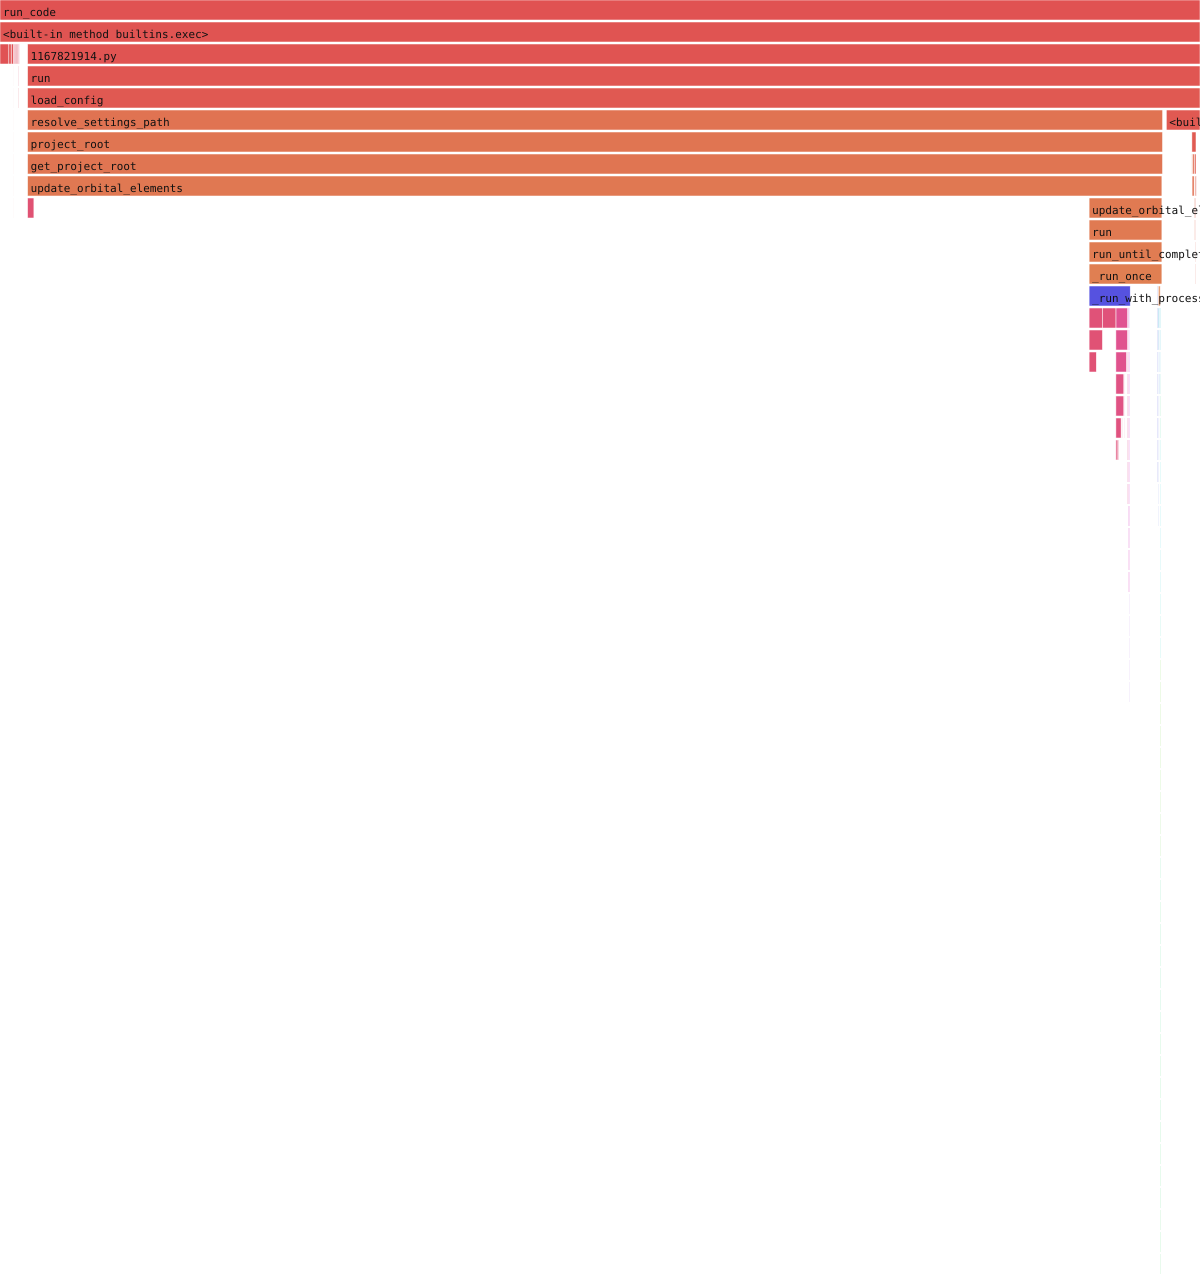

In [7]:
# ── Exibe o flamegraph no notebook ──
from IPython.display import SVG, display

display(SVG(filename=str(svg_path)))


In [8]:
# ── pyinstrument: relatório interativo (HTML) ──
from pyinstrument import Profiler

profiler = Profiler(interval=0.001)
profiler.start()
result2 = orch.run(
    constellations=["GPS"],
    time_range=TR,
    include_satellites=True,
    include_local_sources=False,
    include_radio_sources=False,
    use_processor=True,
)
profiler.stop()

html_path = PROF_DIR / "simulation_pyinstrument.html"
html_path.write_text(profiler.output_html(), encoding="utf-8")
print("Relatório HTML salvo em", html_path)
print(profiler.output_text(unicode=True, color=False))


{'event': 'spacetrack_update_empty_result', 'requested_count': 32, 'norad_ids': [26407, 27663, 28190, 28474, 28874, 29486, 29601, 32260, 32384, 32711, 35752, 36585, 38833, 39166, 39533, 39741, 40105, 40294, 40534, 40730, 41019, 41328, 43873, 44506, 45854, 46826, 48859, 55268, 62339, 64202, 67588, 68791], 'detail': 'SpaceTrack retornou 0 TLEs. Pode significar que: (1) todos os NORAD IDs já foram consultados hoje (cache diário); (2) as credenciais são inválidas; (3) não há TLEs disponíveis para os NORAD IDs solicitados no período.'}


Relatório HTML salvo em data/profiling/simulation_pyinstrument.html

  _     ._   __/__   _ _  _  _ _/_   Recorded: 02:50:37  Samples:  12448
 /_//_/// /_\ / //_// / //_'/ //     Duration: 31.193    CPU time: 31.136
/   _/                      v5.0.2

Profile at /tmp/ipykernel_1195707/98038553.py:5

31.193 <module>  /tmp/ipykernel_1195707/98038553.py:1
└─ 31.193 SimOrchestrator.run  radioskysims_simulation/application/services/sim_orchestrator.py:491
   ├─ 30.296 SimOrchestrator._run_with_processor  radioskysims_simulation/application/services/sim_orchestrator.py:1112
   │  ├─ 10.585 SimulationService._materialize_effective_area  radioskysims_simulation/application/services/simulation_service.py:970
   │  │  └─ 10.585 TODSimulator._resolve_effective_area  radioskysims_simulation/domain/tod/_beam.py:199
   │  │     └─ 10.579 TODSimulator._beam_properties  radioskysims_simulation/domain/tod/_beam.py:87
   │  │        └─ 10.579 Beam.properties  radioskysims_beam/domain/beam/models.py:115


## Artefatos gerados

- `data/profiling/simulation.prof` — perfil cProfile
  (abrir com `snakeviz data/profiling/simulation.prof`).
- `data/profiling/simulation_flamegraph.svg` — flamegraph SVG.
- `data/profiling/simulation_pyinstrument.html` — relatório interativo (navegador).
